# Klasifikasi Citra Penyakit Kulit MonkeyPox (MSLD v2.0)
**Studi Komparasi 3 Arsitektur Deep Learning:** `SimpleCNN`, `ModifiedCNN`, dan `MobileNetV3-Small`

---
### Ringkasan Alur Eksperimen
1. **Dataset:** *Mpox Skin Lesion Dataset v2.0 (MSLD v2.0)* yang terdiri dari 6 kelas (`Chickenpox`, `Cowpox`, `HFMD`, `Healthy`, `Measles`, `Monkeypox`).
2. **Skema Pembagian Data (*Zero Data Leakage*):** Menggunakan partisi standar **5-Fold Cross Validation** bawaan dataset. Data latih (*Train*) menggabungkan citra asli (`Original Images`) dan augmentasi (`Augmented Images`), sedangkan data validasi (`Valid`) dan pengujian (`Test`) menggunakan citra asli murni.
3. **Pre-processing Citra:** Peningkatan kontras lokal menggunakan **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*) pada kanal pencahayaan (*Lightness* / ruang warna LAB), diikuti *resize* `224 × 224` piksel dan normalisasi standar ImageNet.
4. **Model yang Dibandingkan:**
   * **`SimpleCNN`**: Arsitektur CNN dasar 3-blok konvolusi (*baseline from scratch*).
   * **`ModifiedCNN`**: Arsitektur CNN 4-blok konvolusi ganda dengan *Batch Normalization*, aktivasi *SiLU*, blok atensi kanal *Squeeze-and-Excitation (SE)*, dan *Spatial Dropout*.
   * **`MobileNetV3-Small`**: Arsitektur ringan berbasis *Transfer Learning* (*pre-trained* ImageNet).
5. **Metrik Evaluasi:** Rata-rata 5-Fold untuk *Accuracy*, *Macro Precision*, *Macro Recall*, *Macro F1-Score*, *Macro ROC-AUC*, serta *Confusion Matrix*.

---
## Tahap 1: Koneksi Google Drive & Ekstraksi Dataset
Menghubungkan Google Colab ke Google Drive dan mengekstrak arsip `Dataset_Mpox.zip` ke direktori lokal sementara `/content/DATASET_MPOX` agar proses pembacaan gambar berjalan cepat.

In [1]:
from google.colab import drive
import zipfile, os

drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Dataset_Mpox.zip'
extract_path = '/content/DATASET_MPOX'

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

print('Ekstraksi dataset selesai. Isi direktori:', os.listdir(extract_path))

Mounted at /content/drive
Ekstraksi dataset selesai. Isi direktori: ['Augmented Images', 'datalog.xlsx', 'Original Images', 'Keywords.jpg']


---
## Tahap 2: Import Library & Konfigurasi Parameter
Mengimpor seluruh pustaka PyTorch, OpenCV, Scikit-Learn, dan Matplotlib, serta menetapkan hyperparameter eksperimen dalam satu kamus `CONFIG` agar konsisten di seluruh lipatan (*fold*).

> **Catatan Efisiensi:** Parameter `'run_mobilenet': False` menggunakan hasil evaluasi 5-Fold `MobileNetV3-Small` yang telah dijalankan sebelumnya sehingga Colab hanya melatih `SimpleCNN` dan `ModifiedCNN`. Ubah ke `True` jika ingin melatih ulang ketiganya dari awal.

In [2]:
import random
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import MobileNet_V3_Small_Weights

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

CONFIG = {
    'seed': 42,
    'dataset_root': '/content/DATASET_MPOX',
    'output_dir': '/content/outputs',
    'checkpoint_dir': '/content/checkpoints',
    'img_size': 224,
    'batch_size': 64,
    'num_folds': 5,
    'epochs': 15,
    'lr_custom': 1e-3,
    'lr_pretrained': 3e-4,
    'weight_decay': 1e-2,
    'use_clahe': True,
    'num_workers': 2,
    'run_mobilenet': False,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu'
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['checkpoint_dir'], exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(CONFIG['seed'])
print(f"Setup berhasil | Device aktif: {CONFIG['device']} | CLAHE: {CONFIG['use_clahe']}")

Setup berhasil | Device aktif: cuda | CLAHE: True


---
## Tahap 3: Pre-processing Citra (CLAHE) & Dataset Loader
* **`ApplyCLAHE`**: Mengonversi citra RGB ke ruang warna CIELAB (`LAB`) dan menerapkan *Contrast Limited Adaptive Histogram Equalization* hanya pada kanal pencahayaan (`L`) agar detail tekstur lesi lebih tajam tanpa mengubah warna kulit asli.
* **`find_fold_dirs` & `load_images_from_dirs`**: Memetakan direktori `Train` (gabungan *Original + Augmented*), `Valid` (*Original*), dan `Test` (*Original*) secara otomatis pada masing-masing fold tanpa kebocoran data.

In [3]:
class ApplyCLAHE:
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clip_limit = clip_limit
        self.tile_grid_size = tile_grid_size

    def __call__(self, img):
        lab = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l_clahe = cv2.createCLAHE(clipLimit=self.clip_limit, tileGridSize=self.tile_grid_size).apply(l)
        return Image.fromarray(cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2RGB))

def get_transforms(img_size, use_clahe=True):
    pre = [ApplyCLAHE()] if use_clahe else []
    norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    train_tf = transforms.Compose(pre + [
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(0.5),
        transforms.ToTensor(),
        norm
    ])
    eval_tf = transforms.Compose(pre + [
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        norm
    ])
    return train_tf, eval_tf

def find_fold_dirs(root_dir, fold_num):
    orig_train = aug_train = orig_valid = orig_test = None
    fold_tag = f'fold{fold_num}'
    for dirpath, _, _ in os.walk(root_dir):
        norm_path = dirpath.replace('\\', '/').lower()
        base_name = os.path.basename(dirpath).lower()
        if fold_tag in norm_path:
            is_aug = 'aug' in norm_path
            if base_name == 'train':
                if is_aug:
                    aug_train = dirpath
                else:
                    orig_train = dirpath
            elif base_name == 'valid' and not is_aug:
                orig_valid = dirpath
            elif base_name == 'test' and not is_aug:
                orig_test = dirpath
    if not all([orig_train, aug_train, orig_valid, orig_test]):
        raise FileNotFoundError(f'Struktur folder {fold_tag} tidak lengkap di {root_dir}')
    return orig_train, aug_train, orig_valid, orig_test

def load_images_from_dirs(dir_list, class_to_idx):
    filepaths, labels = [], []
    valid_ext = ('.jpg', '.jpeg', '.png', '.bmp')
    for d in dir_list:
        for cls_name, idx in class_to_idx.items():
            cls_dir = os.path.join(d, cls_name)
            for fname in sorted(os.listdir(cls_dir)):
                if fname.lower().endswith(valid_ext):
                    filepaths.append(os.path.join(cls_dir, fname))
                    labels.append(idx)
    return np.array(filepaths), np.array(labels)

class SkinLesionDataset(Dataset):
    def __init__(self, filepaths, labels, transform=None):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        img = Image.open(self.filepaths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, int(self.labels[idx])

orig_tr_1, _, _, _ = find_fold_dirs(CONFIG['dataset_root'], 1)
TARGET_CLASSES = sorted([d for d in os.listdir(orig_tr_1) if os.path.isdir(os.path.join(orig_tr_1, d))])
CLASS_TO_IDX = {c: i for i, c in enumerate(TARGET_CLASSES)}
print(f'Dataset terverifikasi ({len(TARGET_CLASSES)} kelas): {TARGET_CLASSES}')

Dataset terverifikasi (6 kelas): ['Chickenpox', 'Cowpox', 'HFMD', 'Healthy', 'Measles', 'Monkeypox']


---
## Tahap 3A: Pre-processing Cache CLAHE (Optimasi Kecepatan Training)
Menerapkan transformasi **CLAHE** dan *resize* `224 × 224` piksel **satu kali di awal** ke direktori cache `/content/DATASET_MPOX_CLAHE` secara paralel (`ThreadPoolExecutor`). Setelah cache terbentuk, `'use_clahe'` disetel ke `False` agar CPU tidak perlu mengulang proses OpenCV di setiap *epoch* sehingga pelatihan di GPU berjalan jauh lebih cepat.

In [4]:
import shutil
from concurrent.futures import ThreadPoolExecutor

clahe_cache_root = '/content/DATASET_MPOX_CLAHE'
if not os.path.exists(clahe_cache_root):
    clahe_fn = ApplyCLAHE()
    tasks = []
    for root, _, files in os.walk(CONFIG['dataset_root']):
        rel = os.path.relpath(root, CONFIG['dataset_root'])
        dst_dir = os.path.join(clahe_cache_root, rel)
        os.makedirs(dst_dir, exist_ok=True)
        for f in files:
            src_f = os.path.join(root, f)
            dst_f = os.path.join(dst_dir, f)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                tasks.append((src_f, dst_f))
            else:
                shutil.copy2(src_f, dst_f)

    def process_img(pair):
        img = Image.open(pair[0]).convert('RGB').resize((224, 224))
        clahe_fn(img).save(pair[1], quality=95)

    with ThreadPoolExecutor(max_workers=4) as ex:
        list(ex.map(process_img, tasks))

CONFIG['dataset_root'] = clahe_cache_root
CONFIG['use_clahe'] = False  # Sudah diterapkan di cache, tidak perlu diulang tiap epoch
print("Cache CLAHE 224x224 selesai dibuat!")

Cache CLAHE 224x224 selesai dibuat!


---
## Tahap 4: Definisi 3 Arsitektur Model Deep Learning
1. **`SimpleCNN`**: 3 lapisan konvolusi (`32 → 64 → 128` filter) dengan aktivasi *ReLU*, *MaxPooling*, dan *Global Average Pooling*.
2. **`ModifiedCNN`**: 4 blok konvolusi ganda (`32 → 64 → 128 → 256` filter) dengan *BatchNorm2d*, aktivasi *SiLU*, modul perhatian *Squeeze-and-Excitation (`SEBlock`)* untuk membobotkan fitur kanal penting, serta *Dropout2d*.
3. **`MobileNetV3-Small`**: Model *pre-trained* ImageNet dengan modifikasi lapisan klasifikasi akhir (`Dropout(0.3)` + `Linear`).

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64), nn.ReLU(inplace=True),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

class SEBlock(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(ch, ch // r), nn.SiLU(inplace=True),
            nn.Linear(ch // r, ch), nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.fc(x).unsqueeze(-1).unsqueeze(-1)

class ModifiedCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.SiLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.SiLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.1)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.SiLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.SiLU(inplace=True),
            SEBlock(64), nn.MaxPool2d(2), nn.Dropout2d(0.15)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.SiLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.SiLU(inplace=True),
            SEBlock(128), nn.MaxPool2d(2), nn.Dropout2d(0.2)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256), nn.SiLU(inplace=True),
            SEBlock(256), nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(256, 128), nn.SiLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        return self.classifier(x)

def build_model(model_name, num_classes, device):
    if model_name == 'SimpleCNN':
        return SimpleCNN(num_classes).to(device)
    elif model_name == 'ModifiedCNN':
        return ModifiedCNN(num_classes).to(device)
    elif model_name == 'MobileNetV3-Small':
        m = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
        in_f = m.classifier[3].in_features
        m.classifier[3] = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, num_classes))
        return m.to(device)
    raise ValueError(f'Model tidak dikenal: {model_name}')

for name in ['SimpleCNN', 'ModifiedCNN', 'MobileNetV3-Small']:
    m = build_model(name, 6, 'cpu')
    params = sum(p.numel() for p in m.parameters())
    print(f'{name:18s} | Total Parameters: {params:,}')

SimpleCNN          | Total Parameters: 101,894
ModifiedCNN        | Total Parameters: 638,558
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 133MB/s]

MobileNetV3-Small  | Total Parameters: 1,524,006


---
## Tahap 5: Fungsi Training & Evaluasi 5-Fold Cross Validation
Mendefinisikan loop pelatihan per epoch (`train_one_epoch`), evaluasi metrik multi-kelas (`evaluate`), serta orkestrasi 5-Fold Cross Validation (`run_5fold_experiment`) yang menyimpan bobot terbaik berdasarkan *Validation F1-Score*.

In [6]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, preds_all, targets_all = 0.0, [], []
    for imgs, targets in loader:
        imgs, targets = imgs.to(device), targets.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        preds_all.extend(torch.argmax(out, 1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(targets_all, preds_all)

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, y_true, y_pred, y_prob = 0.0, [], [], []
    for imgs, targets in loader:
        imgs, targets = imgs.to(device), targets.to(device)
        out = model(imgs)
        loss = criterion(out, targets)
        probs = torch.softmax(out, 1)
        total_loss += loss.item() * imgs.size(0)
        y_true.extend(targets.cpu().numpy())
        y_pred.extend(torch.argmax(probs, 1).cpu().numpy())
        y_prob.extend(probs.cpu().numpy())
    y_true, y_pred, y_prob = np.array(y_true), np.array(y_pred), np.array(y_prob)
    return {
        'loss': total_loss / len(loader.dataset),
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_score': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro'),
        'y_true': y_true, 'y_pred': y_pred, 'y_prob': y_prob
    }

def run_5fold_experiment(model_name):
    seed_everything(CONFIG['seed'])
    train_tf, eval_tf = get_transforms(CONFIG['img_size'], CONFIG['use_clahe'])
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    epochs = 10 if model_name == 'MobileNetV3-Small' else CONFIG['epochs']
    lr = CONFIG['lr_pretrained'] if model_name == 'MobileNetV3-Small' else CONFIG['lr_custom']

    val_rows, test_rows, histories = [], [], []
    all_y_true, all_y_pred, all_y_prob = [], [], []

    for fold in range(1, CONFIG['num_folds'] + 1):
        print(f'\n{"="*45}\n[{model_name}] FOLD {fold}/{CONFIG["num_folds"]}\n{"="*45}')
        orig_tr, aug_tr, orig_val, orig_ts = find_fold_dirs(CONFIG['dataset_root'], fold)
        X_tr, y_tr = load_images_from_dirs([orig_tr, aug_tr], CLASS_TO_IDX)
        X_va, y_va = load_images_from_dirs([orig_val], CLASS_TO_IDX)
        X_ts, y_ts = load_images_from_dirs([orig_ts], CLASS_TO_IDX)

        tr_loader = DataLoader(SkinLesionDataset(X_tr, y_tr, train_tf), batch_size=CONFIG['batch_size'], shuffle=True, num_workers=CONFIG['num_workers'])
        va_loader = DataLoader(SkinLesionDataset(X_va, y_va, eval_tf), batch_size=CONFIG['batch_size'], shuffle=False, num_workers=CONFIG['num_workers'])
        ts_loader = DataLoader(SkinLesionDataset(X_ts, y_ts, eval_tf), batch_size=CONFIG['batch_size'], shuffle=False, num_workers=CONFIG['num_workers'])

        model = build_model(model_name, len(TARGET_CLASSES), CONFIG['device'])
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

        best_f1 = 0.0
        ckpt = os.path.join(CONFIG['checkpoint_dir'], f'{model_name}_fold{fold}.pth')
        hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

        for ep in range(1, epochs + 1):
            tr_loss, tr_acc = train_one_epoch(model, tr_loader, criterion, optimizer, CONFIG['device'])
            va_m = evaluate(model, va_loader, criterion, CONFIG['device'])
            scheduler.step()
            hist['train_loss'].append(tr_loss); hist['val_loss'].append(va_m['loss'])
            hist['train_acc'].append(tr_acc); hist['val_acc'].append(va_m['accuracy'])
            print(f"Ep [{ep:02d}/{epochs:02d}] | TrLoss: {tr_loss:.4f} TrAcc: {tr_acc:.4f} | ValAcc: {va_m['accuracy']:.4f} ValF1: {va_m['f1_score']:.4f} AUC: {va_m['roc_auc']:.4f}")
            if va_m['f1_score'] >= best_f1:
                best_f1 = va_m['f1_score']
                torch.save(model.state_dict(), ckpt)

        histories.append(hist)
        model.load_state_dict(torch.load(ckpt, map_location=CONFIG['device']))
        b_val = evaluate(model, va_loader, criterion, CONFIG['device'])
        b_tst = evaluate(model, ts_loader, criterion, CONFIG['device'])

        val_rows.append({'Model': model_name, 'Fold': f'Fold {fold}', 'Split': 'Validation', **{k: b_val[k] for k in ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']}})
        test_rows.append({'Model': model_name, 'Fold': f'Fold {fold}', 'Split': 'Test', **{k: b_tst[k] for k in ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']}})
        all_y_true.extend(b_tst['y_true']); all_y_pred.extend(b_tst['y_pred']); all_y_prob.extend(b_tst['y_prob'])

    return pd.DataFrame(val_rows), pd.DataFrame(test_rows), histories, (np.array(all_y_true), np.array(all_y_pred), np.array(all_y_prob))

---
## Tahap 6: Eksekusi Pelatihan & Rekapitulasi Perbandingan 3 Model
Menjalankan eksperimen 5-Fold Cross Validation dan menggabungkan hasil seluruh model ke dalam file CSV (`metrics_per_fold_3models.csv` dan `comparison_mean_3models.csv`).

In [7]:
models_to_run = ['SimpleCNN', 'ModifiedCNN'] + (['MobileNetV3-Small'] if CONFIG['run_mobilenet'] else [])
all_val_dfs, all_test_dfs, all_histories, all_preds_dict = [], [], {}, {}

for m_name in models_to_run:
    df_v, df_t, hist, preds = run_5fold_experiment(m_name)
    all_val_dfs.append(df_v)
    all_test_dfs.append(df_t)
    all_histories[m_name] = hist
    all_preds_dict[m_name] = preds

if not CONFIG['run_mobilenet']:
    mobilenet_val = pd.DataFrame([
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 1', 'Split': 'Validation', 'accuracy': 0.784722, 'precision': 0.802881, 'recall': 0.741532, 'f1_score': 0.761868, 'roc_auc': 0.961101},
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 2', 'Split': 'Validation', 'accuracy': 0.871951, 'precision': 0.850494, 'recall': 0.875256, 'f1_score': 0.860533, 'roc_auc': 0.984811},
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 3', 'Split': 'Validation', 'accuracy': 0.784314, 'precision': 0.769434, 'recall': 0.776592, 'f1_score': 0.771873, 'roc_auc': 0.896345},
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 4', 'Split': 'Validation', 'accuracy': 0.873333, 'precision': 0.871594, 'recall': 0.813888, 'f1_score': 0.836528, 'roc_auc': 0.953930},
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 5', 'Split': 'Validation', 'accuracy': 0.818182, 'precision': 0.822503, 'recall': 0.797205, 'f1_score': 0.800212, 'roc_auc': 0.967134},
    ])
    mobilenet_test = pd.DataFrame([
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 1', 'Split': 'Test', 'accuracy': 0.837838, 'precision': 0.921131, 'recall': 0.773093, 'f1_score': 0.814182, 'roc_auc': 0.907756},
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 2', 'Split': 'Test', 'accuracy': 0.792683, 'precision': 0.784788, 'recall': 0.799487, 'f1_score': 0.789481, 'roc_auc': 0.936467},
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 3', 'Split': 'Test', 'accuracy': 0.828125, 'precision': 0.822150, 'recall': 0.799684, 'f1_score': 0.808479, 'roc_auc': 0.948217},
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 4', 'Split': 'Test', 'accuracy': 0.765432, 'precision': 0.792807, 'recall': 0.787144, 'f1_score': 0.784244, 'roc_auc': 0.969058},
        {'Model': 'MobileNetV3-Small', 'Fold': 'Fold 5', 'Split': 'Test', 'accuracy': 0.904762, 'precision': 0.940241, 'recall': 0.859788, 'f1_score': 0.880770, 'roc_auc': 0.979549},
    ])
    all_val_dfs.append(mobilenet_val)
    all_test_dfs.append(mobilenet_test)

df_folds_all = pd.concat(all_val_dfs + all_test_dfs, ignore_index=True)
df_folds_all.to_csv(os.path.join(CONFIG['output_dir'], 'metrics_per_fold_3models.csv'), index=False)

df_comparison = df_folds_all.groupby(['Model', 'Split'])[['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']].mean().reset_index()
df_comparison.to_csv(os.path.join(CONFIG['output_dir'], 'comparison_mean_3models.csv'), index=False)

print('\n=== REKAPITULASI RATA-RATA 5-FOLD (3 MODEL) ===')
display(df_comparison)


[SimpleCNN] FOLD 1/5
Ep [01/15] | TrLoss: 1.6375 TrAcc: 0.3700 | ValAcc: 0.3542 ValF1: 0.1338 AUC: 0.6069
Ep [02/15] | TrLoss: 1.5157 TrAcc: 0.4389 | ValAcc: 0.4236 ValF1: 0.2679 AUC: 0.6755
Ep [03/15] | TrLoss: 1.4487 TrAcc: 0.4834 | ValAcc: 0.4583 ValF1: 0.2663 AUC: 0.7021
Ep [04/15] | TrLoss: 1.3879 TrAcc: 0.5186 | ValAcc: 0.4722 ValF1: 0.2725 AUC: 0.7186
Ep [05/15] | TrLoss: 1.3306 TrAcc: 0.5443 | ValAcc: 0.4236 ValF1: 0.2371 AUC: 0.7199
Ep [06/15] | TrLoss: 1.2909 TrAcc: 0.5633 | ValAcc: 0.4653 ValF1: 0.2745 AUC: 0.7355
Ep [07/15] | TrLoss: 1.2521 TrAcc: 0.5888 | ValAcc: 0.4861 ValF1: 0.2928 AUC: 0.7496
Ep [08/15] | TrLoss: 1.2166 TrAcc: 0.6067 | ValAcc: 0.4653 ValF1: 0.2807 AUC: 0.7583
Ep [09/15] | TrLoss: 1.1904 TrAcc: 0.6174 | ValAcc: 0.4653 ValF1: 0.2958 AUC: 0.7495
Ep [10/15] | TrLoss: 1.1662 TrAcc: 0.6359 | ValAcc: 0.4722 ValF1: 0.3226 AUC: 0.7612
Ep [11/15] | TrLoss: 1.1448 TrAcc: 0.6492 | ValAcc: 0.4653 ValF1: 0.3152 AUC: 0.7525
Ep [12/15] | TrLoss: 1.1263 TrAcc: 0.6592 |

,Model,Split,accuracy,precision,recall,f1_score,roc_auc
0,MobileNetV3-Small,Test,0.825768,0.852223,0.803839,0.815431,0.948209
1,MobileNetV3-Small,Validation,0.826500,0.823381,0.800895,0.806203,0.952664
2,ModifiedCNN,Test,0.560480,0.557640,0.432410,0.429894,0.824371
3,ModifiedCNN,Validation,0.569503,0.528127,0.472855,0.469077,0.815081
4,SimpleCNN,Test,0.512250,0.388989,0.360345,0.340357,0.766719
5,SimpleCNN,Validation,0.503939,0.387269,0.370880,0.353880,0.761689


---
## Tahap 7: Visualisasi Grafik Perbandingan & Evaluasi Model
Menghasilkan dan menyimpan grafik evaluasi resolusi tinggi (300 DPI) ke dalam folder `/content/outputs` untuk laporan dan repositori GitHub:
1. **Grafik Batang Perbandingan 3 Model** (*Test Set Mean*).
2. **Kurva Training & Validation** (*Loss* & *Accuracy*).
3. **Confusion Matrix** akumulasi 5-Fold *Test Set*.
4. **Kurva Multi-Class ROC-AUC**.

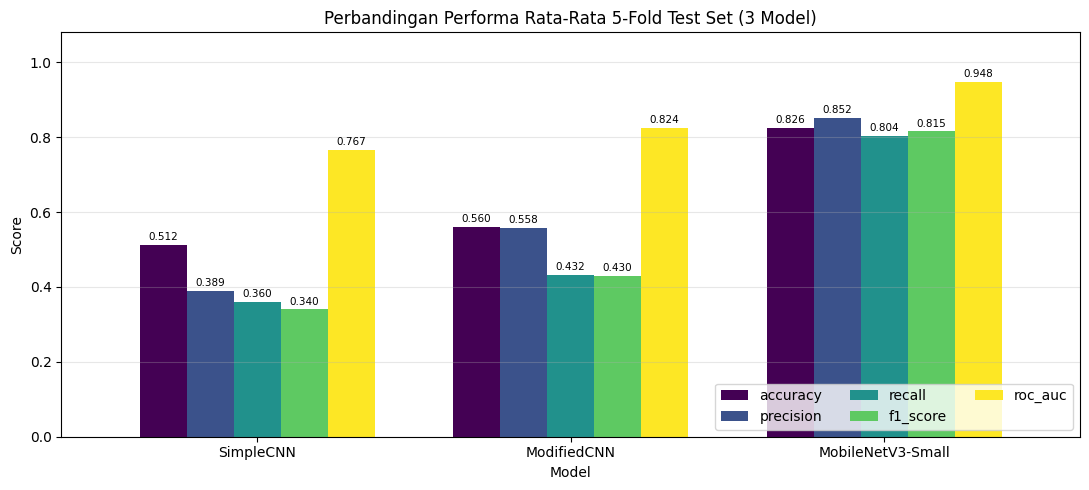

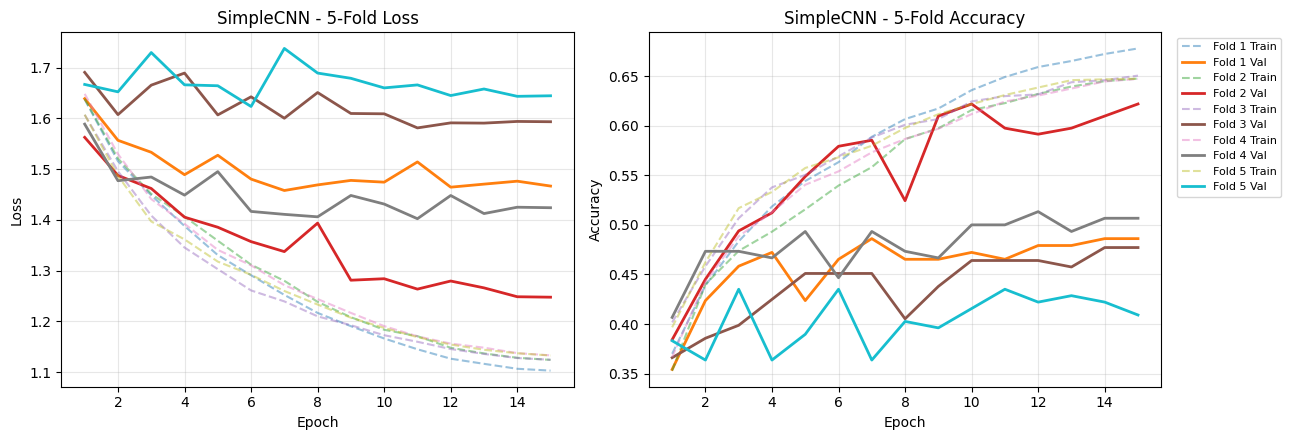

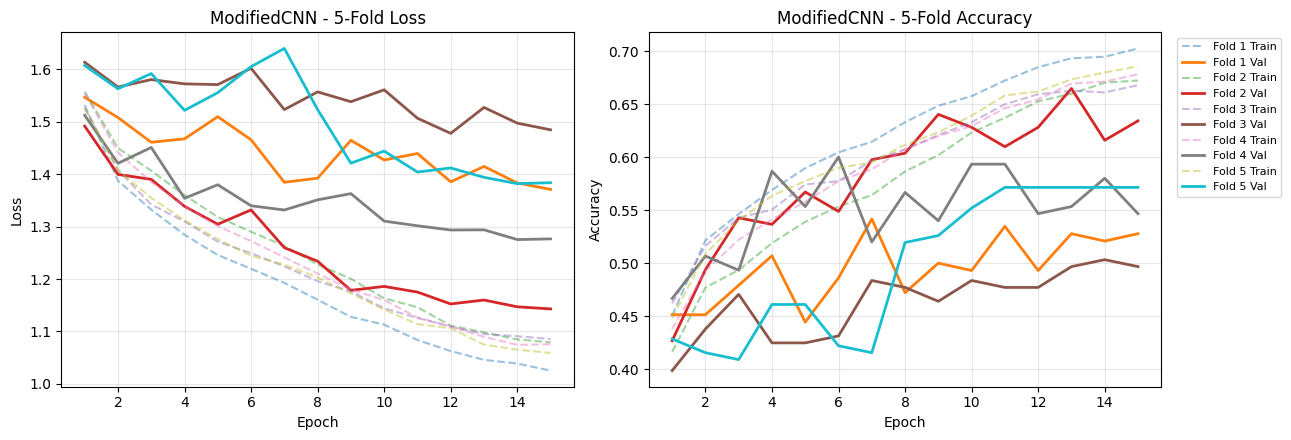

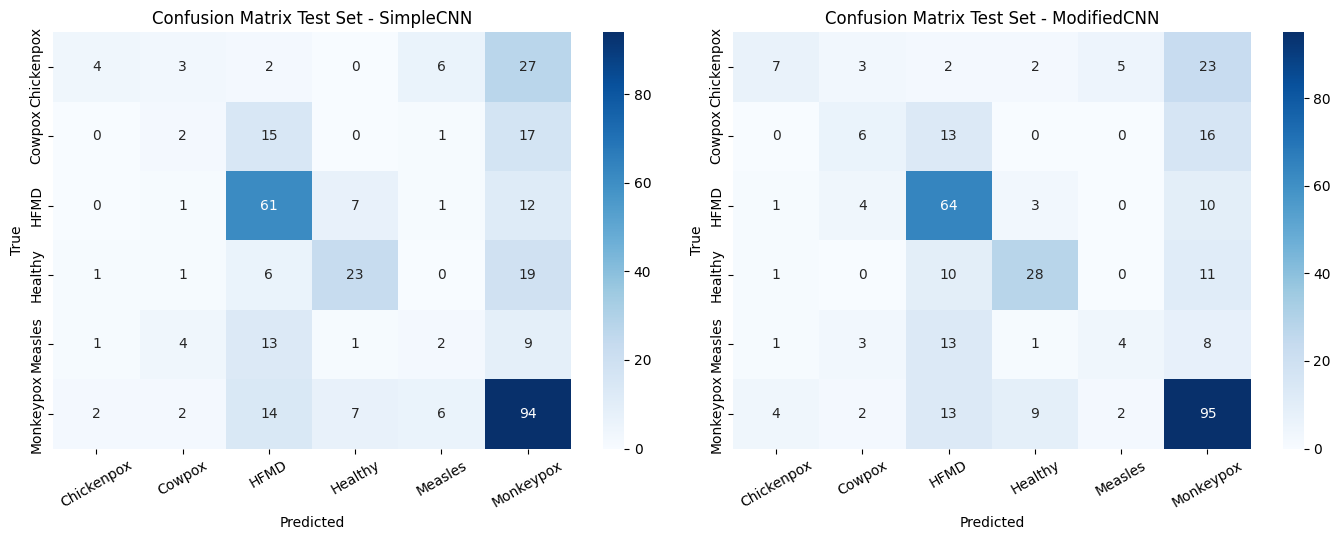

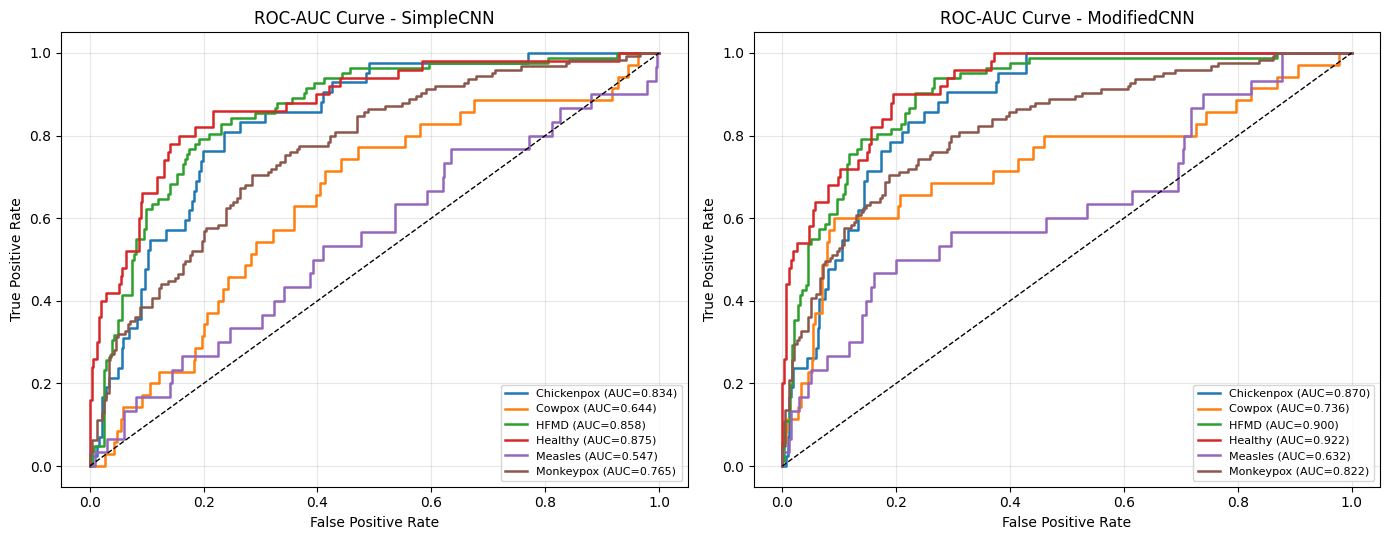

In [8]:
# 1. Grafik Perbandingan Rata-Rata Metrik Test Set (3 Model)
df_test_comp = df_comparison[df_comparison['Split'] == 'Test'].set_index('Model').loc[['SimpleCNN', 'ModifiedCNN', 'MobileNetV3-Small']]
ax = df_test_comp.plot(kind='bar', figsize=(11, 5), width=0.75, colormap='viridis')
plt.title('Perbandingan Performa Rata-Rata 5-Fold Test Set (3 Model)')
plt.ylabel('Score')
plt.ylim(0, 1.08)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower right', ncol=3)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=7.5, padding=2)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'comparison_3models_bar.png'), dpi=300)
plt.show()

# 2. Kurva Training & Validation (Loss & Accuracy)
for m_name, hists in all_histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    ep_range = range(1, len(hists[0]['train_loss']) + 1)
    for f_i, h in enumerate(hists, 1):
        axes[0].plot(ep_range, h['train_loss'], '--', alpha=0.45, label=f'Fold {f_i} Train')
        axes[0].plot(ep_range, h['val_loss'], lw=2, label=f'Fold {f_i} Val')
        axes[1].plot(ep_range, h['train_acc'], '--', alpha=0.45, label=f'Fold {f_i} Train')
        axes[1].plot(ep_range, h['val_acc'], lw=2, label=f'Fold {f_i} Val')
    axes[0].set_title(f'{m_name} - 5-Fold Loss')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].grid(True, alpha=0.3)
    axes[1].set_title(f'{m_name} - 5-Fold Accuracy')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].grid(True, alpha=0.3)
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['output_dir'], f'training_curves_{m_name}.png'), dpi=300, bbox_inches='tight')
    plt.show()

# 3. Confusion Matrix Akumulasi Test Set
fig, axes = plt.subplots(1, len(all_preds_dict), figsize=(7 * len(all_preds_dict), 5.5))
if len(all_preds_dict) == 1:
    axes = [axes]
for ax_i, (m_name, (yt, yp, _)) in enumerate(all_preds_dict.items()):
    cm = confusion_matrix(yt, yp)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES, ax=axes[ax_i])
    axes[ax_i].set_title(f'Confusion Matrix Test Set - {m_name}')
    axes[ax_i].set_xlabel('Predicted'); axes[ax_i].set_ylabel('True')
    axes[ax_i].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'confusion_matrix_custom_models.png'), dpi=300)
plt.show()

# 4. Multi-Class ROC-AUC Curve
fig, axes = plt.subplots(1, len(all_preds_dict), figsize=(7 * len(all_preds_dict), 5.5))
if len(all_preds_dict) == 1:
    axes = [axes]
for ax_i, (m_name, (yt, _, yprob)) in enumerate(all_preds_dict.items()):
    yt_bin = label_binarize(yt, classes=list(range(len(TARGET_CLASSES))))
    for c_idx in range(len(TARGET_CLASSES)):
        fpr, tpr, _ = roc_curve(yt_bin[:, c_idx], yprob[:, c_idx])
        axes[ax_i].plot(fpr, tpr, lw=1.8, label=f'{TARGET_CLASSES[c_idx]} (AUC={auc(fpr, tpr):.3f})')
    axes[ax_i].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[ax_i].set_title(f'ROC-AUC Curve - {m_name}')
    axes[ax_i].set_xlabel('False Positive Rate'); axes[ax_i].set_ylabel('True Positive Rate')
    axes[ax_i].legend(loc='lower right', fontsize=8); axes[ax_i].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'roc_auc_custom_models.png'), dpi=300)
plt.show()